# Cell 1 — Import required libraries

In [1]:
# Import utilities for file management and warning control.
import os
import glob
import zipfile
import re
import html
import warnings

# Import libraries for data analysis and visualization.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting data and building machine learning pipelines.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# Import the required sentiment classification algorithms.
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Import classification evaluation metrics.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configure consistent plots and reproducible results.
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


# Cell 2 — Install and download NLTK resources

In [2]:
# Install NLTK for stopword removal, tokenization, and lemmatization.
%pip -q install nltk

# Import NLTK functions required for text preprocessing.
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download the language resources needed by this notebook.
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Initialize the English stopword list and lemmatizer.
STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()

print("NLTK resources are ready.")

NLTK resources are ready.


# Cell 3 — Mount Google Drive

In [3]:
# Import the Google Colab Google Drive integration.
from google.colab import drive

# Mount Drive to access the uploaded sentiment dataset.
drive.mount("/content/drive")

# Create a folder to store plots, metrics, and trained model files.
OUTPUT_DIR = "/content/drive/MyDrive/NLP_Sentiment_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display the folder where project outputs will be saved.
print("Output directory:", OUTPUT_DIR)

Mounted at /content/drive
Output directory: /content/drive/MyDrive/NLP_Sentiment_Results


# Cell 4 — Find and load the CSV dataset

In [4]:

# Search Google Drive for the uploaded IMDb dataset CSV file.
import glob
import os
import pandas as pd

# Find the dataset inside Google Drive's MyDrive folder.
csv_files = glob.glob(
    "/content/drive/MyDrive/**/IMDB Dataset.csv",
    recursive=True
)

# If the exact filename is not found, search for other IMDb CSV filenames.
if not csv_files:
    csv_files = glob.glob(
        "/content/drive/MyDrive/**/*IMDB*.csv",
        recursive=True
    )

# Stop if the dataset cannot be found.
if not csv_files:
    raise FileNotFoundError(
        "IMDB Dataset.csv was not found in Google Drive. "
        "Upload it to MyDrive and run this cell again."
    )

# Select the dataset file.
DATA_PATH = csv_files[0]

# Load the IMDb reviews dataset.
df = pd.read_csv(DATA_PATH)

# Display the file path, shape, columns, and first five rows.
print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset path: /content/drive/MyDrive/IMDB Dataset.csv
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


# Cell 5 — Inspect columns and missing values

In [5]:
# Display the column names to understand the dataset structure.
print("Dataset columns:")
print(df.columns.tolist())

# Display data types and non-null counts.
print("\nDataset information:")
df.info()

# Count missing values in every column.
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

# Check the number of duplicate rows.
print("\nDuplicate rows:", df.duplicated().sum())

# Display descriptive statistics for all columns.
display(df.describe(include="all").T)

Dataset columns:
['review', 'sentiment']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing values:


,Missing Count
review,0
sentiment,0



Duplicate rows: 418


,count,unique,top,freq
review,50000,49582,Loved today's show!!! It was a variety and not...,5
sentiment,50000,2,positive,25000


# Cell 6 — Identify text and sentiment columns

In [6]:
# Normalize column names to simplify matching.
df.columns = df.columns.str.strip().str.lower()

# Define common names for review text columns.
text_candidates = [
    "text", "review", "review_text", "content",
    "comment", "sentence", "review_body"
]

# Define common names for sentiment label columns.
label_candidates = [
    "sentiment", "label", "polarity", "target",
    "class", "rating_sentiment"
]

# Select the first matching text and label columns.
TEXT_COLUMN = next(
    (col for col in text_candidates if col in df.columns),
    None
)

LABEL_COLUMN = next(
    (col for col in label_candidates if col in df.columns),
    None
)

# Display available columns if automatic identification fails.
if TEXT_COLUMN is None or LABEL_COLUMN is None:
    raise ValueError(
        "Could not automatically identify both text and sentiment columns. "
        f"Available columns: {df.columns.tolist()}. "
        "Set TEXT_COLUMN and LABEL_COLUMN manually in this cell."
    )

# Keep only the review text and sentiment label columns.
df = df[[TEXT_COLUMN, LABEL_COLUMN]].copy()

# Remove rows where the text or sentiment label is missing.
df = df.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()

# Convert review text to strings and remove leading/trailing spaces.
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str).str.strip()

# Remove empty review texts.
df = df[df[TEXT_COLUMN] != ""].copy()

# Remove duplicate text-label records.
df = df.drop_duplicates(subset=[TEXT_COLUMN, LABEL_COLUMN])

# Display the selected columns and cleaned dataset size.
print("Text column:", TEXT_COLUMN)
print("Label column:", LABEL_COLUMN)
print("Cleaned dataset shape:", df.shape)
display(df.head())

Text column: review
Label column: sentiment
Cleaned dataset shape: (49582, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


# Cell 7 — Inspect sentiment labels

Unique labels:
['positive' 'negative']

Label distribution:


,Count
sentiment,
positive,24884
negative,24698


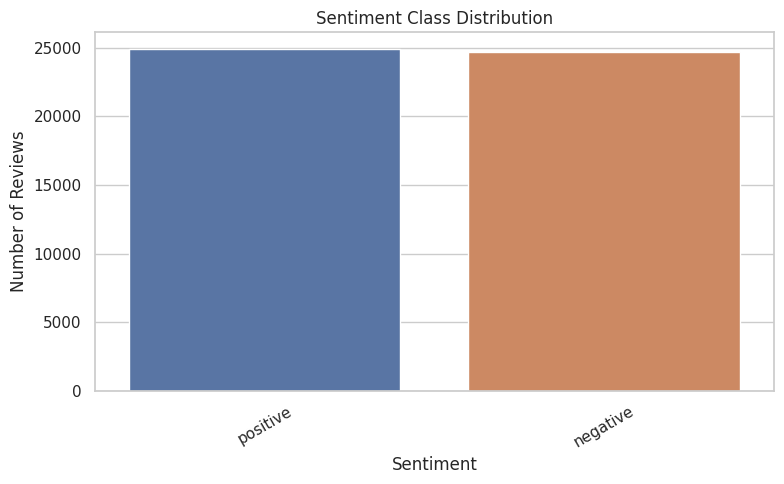

In [7]:
# Display the unique sentiment labels and their frequencies.
print("Unique labels:")
print(df[LABEL_COLUMN].unique())

print("\nLabel distribution:")
display(df[LABEL_COLUMN].value_counts().to_frame("Count"))

# Visualize the distribution of sentiment classes.
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x=LABEL_COLUMN,
    hue=LABEL_COLUMN,
    order=df[LABEL_COLUMN].value_counts().index,
    legend=False
)

# Add descriptive labels and rotate category names if necessary.
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30)
plt.tight_layout()

# Save the class distribution chart.
plt.savefig(f"{OUTPUT_DIR}/01_sentiment_distribution.png", dpi=300)
plt.show()

# Cell 8 — Standardize sentiment labels

In [8]:
# Normalize string labels to make common positive and negative categories consistent.
def normalize_sentiment_label(value):
    # Convert text labels to lowercase and remove surrounding spaces.
    if isinstance(value, str):
        value = value.strip().lower()

        # Map common positive label names to a standard label.
        if value in {"positive", "pos", "1", "good", "favorable"}:
            return "positive"

        # Map common negative label names to a standard label.
        if value in {"negative", "neg", "0", "bad", "unfavorable"}:
            return "negative"

        # Preserve other labels for inspection instead of guessing.
        return value

    # Preserve numeric labels so their meaning can be checked separately.
    return value

# Apply label normalization.
df[LABEL_COLUMN] = df[LABEL_COLUMN].apply(normalize_sentiment_label)

# Display the resulting classes and counts.
print("Normalized labels:")
print(df[LABEL_COLUMN].value_counts(dropna=False))

# Ensure this project is a binary positive/negative sentiment task.
valid_labels = {"positive", "negative"}

if set(df[LABEL_COLUMN].unique()) != valid_labels:
    raise ValueError(
        "The dataset does not currently contain exactly 'positive' and "
        "'negative' labels after normalization. Inspect the label values "
        "and edit this cell to map your dataset's labels correctly. "
        f"Current labels: {df[LABEL_COLUMN].unique().tolist()}"
    )

print("Binary sentiment labels are ready.")

Normalized labels:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64
Binary sentiment labels are ready.


# Cell 9 — Clean, tokenize, remove stopwords and lemmatize text

In [9]:
# Preserve important negation words because they can reverse sentiment.
CUSTOM_STOP_WORDS = STOP_WORDS - {"no", "nor", "not"}

# Create a text-cleaning function for customer reviews.
def preprocess_text(text):
    # Convert the input to a string and decode HTML entities.
    text = html.unescape(str(text))

    # Remove HTML tags from the review.
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert all text to lowercase.
    text = text.lower()

    # Replace URLs and email addresses with spaces.
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", text)

    # Keep alphabetic words and remove punctuation, digits, and special characters.
    tokens = re.findall(r"\b[a-z]+\b", text)

    # Remove English stopwords and lemmatize the remaining tokens.
    cleaned_tokens = [
        LEMMATIZER.lemmatize(token)
        for token in tokens
        if token not in CUSTOM_STOP_WORDS and len(token) > 1
    ]

    # Return the processed review as a space-separated string.
    return " ".join(cleaned_tokens)

# Apply text preprocessing to every review.
df["cleaned_text"] = df[TEXT_COLUMN].apply(preprocess_text)

# Remove reviews that become empty after preprocessing.
df = df[df["cleaned_text"].str.strip() != ""].copy()

# Display original and cleaned examples.
display(df[[TEXT_COLUMN, "cleaned_text", LABEL_COLUMN]].head(10))

# Save the cleaned dataset for inspection.
df.to_csv(f"{OUTPUT_DIR}/cleaned_sentiment_reviews.csv", index=False)

,review,cleaned_text,sentiment
0,One of the other reviewers has mentioned that ...,one reviewer mentioned watching oz episode hoo...,positive
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,positive
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,Basically there's a family where a little boy ...,basically family little boy jake think zombie ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei love time money visually stunnin...,positive
5,"Probably my all-time favorite movie, a story o...",probably time favorite movie story selflessnes...,positive
6,I sure would like to see a resurrection of a u...,sure would like see resurrection dated seahunt...,positive
7,"This show was an amazing, fresh & innovative i...",show amazing fresh innovative idea first aired...,negative
8,Encouraged by the positive comments about this...,encouraged positive comment film looking forwa...,negative
9,If you like original gut wrenching laughter yo...,like original gut wrenching laughter like movi...,positive


# Cell 10 — Review text before and after cleaning

In [10]:
# Select one review to demonstrate the text preprocessing process.
sample_review = df.iloc[0][TEXT_COLUMN]

# Process the sample review using the preprocessing function.
cleaned_sample = preprocess_text(sample_review)

# Display the original and cleaned review side by side.
print("Original review:")
print(sample_review)

print("\nCleaned review:")
print(cleaned_sample)

Original review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

# Cell 11 — Split the data into training and testing sets

In [11]:
# Use cleaned review text as the model input and sentiment labels as the target.
X = df["cleaned_text"]
y = df[LABEL_COLUMN]

# Split the dataset while preserving the proportion of each sentiment class.
# The test set remains separate for final model evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Display the number of samples in each subset.
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Display sentiment proportions in each subset.
print("\nTraining label distribution:")
display(y_train.value_counts(normalize=True).to_frame("Proportion"))

print("\nTesting label distribution:")
display(y_test.value_counts(normalize=True).to_frame("Proportion"))

Training samples: 39665
Testing samples: 9917

Training label distribution:


,Proportion
sentiment,
positive,0.501878
negative,0.498122



Testing label distribution:


,Proportion
sentiment,
positive,0.501865
negative,0.498135


# Cell 12 — Build the TF-IDF + Multinomial Naive Bayes pipeline

In [12]:
# Build a pipeline that converts review text into TF-IDF features and trains Naive Bayes.
# The vectorizer is fitted only on training data to avoid vocabulary leakage.
nb_pipeline = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB())
])

# Train the complete pipeline on the training reviews.
nb_pipeline.fit(X_train, y_train)

# Predict sentiment labels for the unseen test reviews.
nb_predictions = nb_pipeline.predict(X_test)

# Obtain predicted probabilities for each sentiment class.
nb_probabilities = nb_pipeline.predict_proba(X_test)

print("TF-IDF + Multinomial Naive Bayes training completed.")

TF-IDF + Multinomial Naive Bayes training completed.


# Cell 13 — Train TF-IDF + Logistic Regression

In [13]:
# Build a second pipeline using the same TF-IDF settings and Logistic Regression.
lr_pipeline = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Train Logistic Regression on the same training data.
lr_pipeline.fit(X_train, y_train)

# Predict sentiment labels for the test reviews.
lr_predictions = lr_pipeline.predict(X_test)

# Calculate class probabilities for the test reviews.
lr_probabilities = lr_pipeline.predict_proba(X_test)

print("TF-IDF + Logistic Regression training completed.")

TF-IDF + Logistic Regression training completed.


# Cell 14 — Evaluate accuracy, precision, recall and F1-score

In [14]:
# Define a helper function to calculate classification metrics.
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="positive", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="positive", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, pos_label="positive", zero_division=0
        )
    }

# Evaluate both trained models on the same test set.
results = pd.DataFrame([
    evaluate_model("Multinomial Naive Bayes", y_test, nb_predictions),
    evaluate_model("Logistic Regression", y_test, lr_predictions)
])

# Sort the models by F1-score for an initial comparison.
results = results.sort_values("F1 Score", ascending=False).reset_index(drop=True)

# Display the evaluation metrics.
print("Test-set performance:")
display(results.round(4))

# Save the model comparison table to Google Drive.
results.to_csv(f"{OUTPUT_DIR}/model_comparison.csv", index=False)

Test-set performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8953,0.8884,0.9052,0.8967
1,Multinomial Naive Bayes,0.8648,0.8565,0.8776,0.8669


# Cell 15 — Classification reports

In [15]:
# Print detailed classification metrics for Multinomial Naive Bayes.
print("MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    labels=["negative", "positive"],
    zero_division=0
))

# Print detailed classification metrics for Logistic Regression.
print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    labels=["negative", "positive"],
    zero_division=0
))

# Save both classification reports to a text file.
with open(
    f"{OUTPUT_DIR}/classification_reports.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("MULTINOMIAL NAIVE BAYES\n")
    file.write(classification_report(
        y_test, nb_predictions,
        labels=["negative", "positive"],
        zero_division=0
    ))

    file.write("\nLOGISTIC REGRESSION\n")
    file.write(classification_report(
        y_test, lr_predictions,
        labels=["negative", "positive"],
        zero_division=0
    ))

print("Classification reports saved.")

MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.87      0.85      0.86      4940
    positive       0.86      0.88      0.87      4977

    accuracy                           0.86      9917
   macro avg       0.87      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.90      0.89      0.89      4940
    positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917

Classification reports saved.


# Cell 16 — Confusion matrices

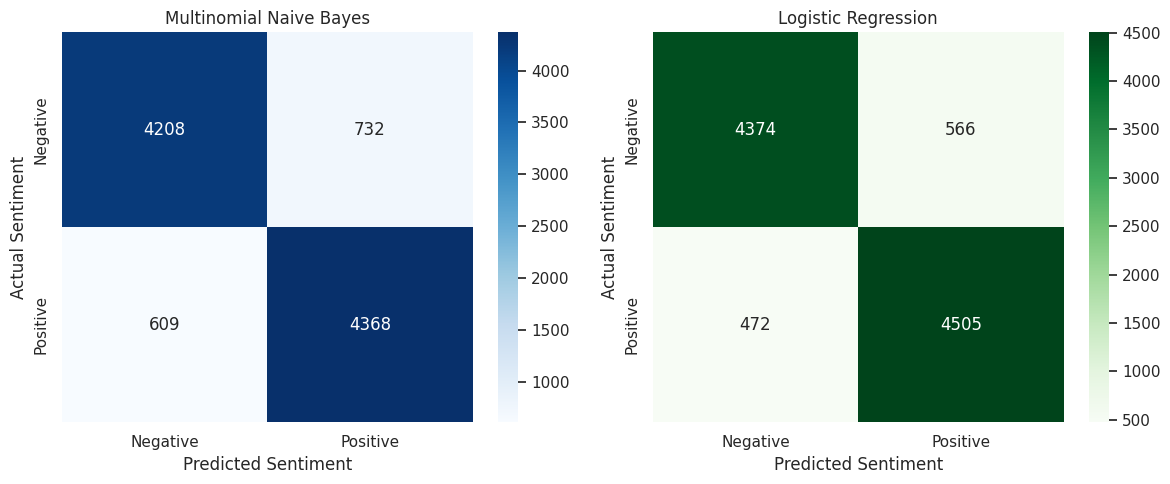

In [16]:
# Calculate confusion matrices using the same class order for both models.
nb_cm = confusion_matrix(
    y_test, nb_predictions, labels=["negative", "positive"]
)
lr_cm = confusion_matrix(
    y_test, lr_predictions, labels=["negative", "positive"]
)

# Create side-by-side plots for model comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the Naive Bayes confusion matrix.
sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0]
)
axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted Sentiment")
axes[0].set_ylabel("Actual Sentiment")

# Plot the Logistic Regression confusion matrix.
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[1]
)
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted Sentiment")
axes[1].set_ylabel("Actual Sentiment")

# Save and display the comparison figure.
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_confusion_matrices.png", dpi=300)
plt.show()

# Cell 17 — Visualize model performance

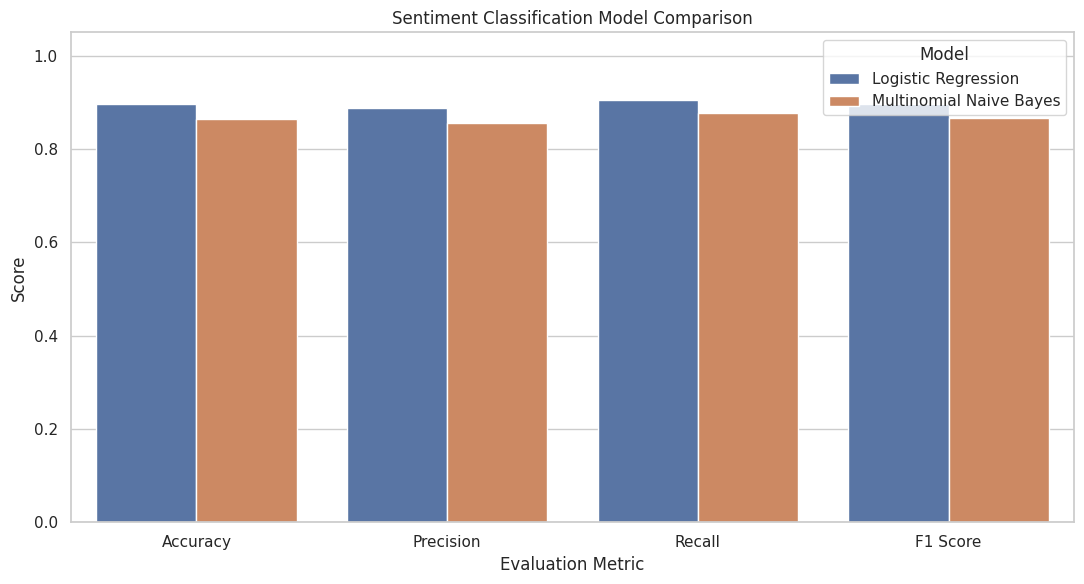

In [17]:
# Convert metric results to a format suitable for grouped bar charts.
metrics_long = results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

# Plot the classification metrics for both models.
plt.figure(figsize=(11, 6))
sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Model"
)

# Add labels and use a consistent score range.
plt.title("Sentiment Classification Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.tight_layout()

# Save and display the comparison plot.
plt.savefig(f"{OUTPUT_DIR}/03_model_comparison.png", dpi=300)
plt.show()

# Cell 18 — Cross-validation benchmark

In [18]:
# Create stratified folds so each fold preserves the class proportions.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define the metrics used to benchmark both text-classification pipelines.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Evaluate Naive Bayes using training data and five-fold cross-validation.
nb_cv = cross_validate(
    nb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Evaluate Logistic Regression using the same folds.
lr_cv = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Summarize the mean and standard deviation of cross-validation scores.
cv_results = pd.DataFrame([
    {
        "Model": "Multinomial Naive Bayes",
        "Mean Accuracy": nb_cv["test_accuracy"].mean(),
        "Accuracy Std": nb_cv["test_accuracy"].std(),
        "Mean F1": nb_cv["test_f1"].mean(),
        "F1 Std": nb_cv["test_f1"].std()
    },
    {
        "Model": "Logistic Regression",
        "Mean Accuracy": lr_cv["test_accuracy"].mean(),
        "Accuracy Std": lr_cv["test_accuracy"].std(),
        "Mean F1": lr_cv["test_f1"].mean(),
        "F1 Std": lr_cv["test_f1"].std()
    }
])

# Display and save the cross-validation benchmark.
display(cv_results.round(4))
cv_results.to_csv(f"{OUTPUT_DIR}/cross_validation_results.csv", index=False)

,Model,Mean Accuracy,Accuracy Std,Mean F1,F1 Std
0,Multinomial Naive Bayes,0.8629,0.0046,NaN,NaN
1,Logistic Regression,0.8928,0.0023,NaN,NaN


# Cell 19 — Find the most influential positive and negative words

Terms associated with negative sentiment:


,Term,Coefficient
4925,worst,-9.044851
282,awful,-7.777006
293,bad,-7.117219
452,boring,-6.458367
4798,waste,-6.405703
3361,poor,-5.817325
4417,terrible,-5.634235
2058,horrible,-4.950180
1194,dull,-4.879360
1438,fails,-4.855249


Terms associated with positive sentiment:


,Term,Coefficient
1878,great,6.651574
1371,excellent,6.532928
3264,perfect,5.484760
150,amazing,5.010392
4905,wonderful,4.617804
3119,one best,4.242885
374,best,4.202607
488,brilliant,4.142266
2533,loved,4.139103
2907,must see,4.115012


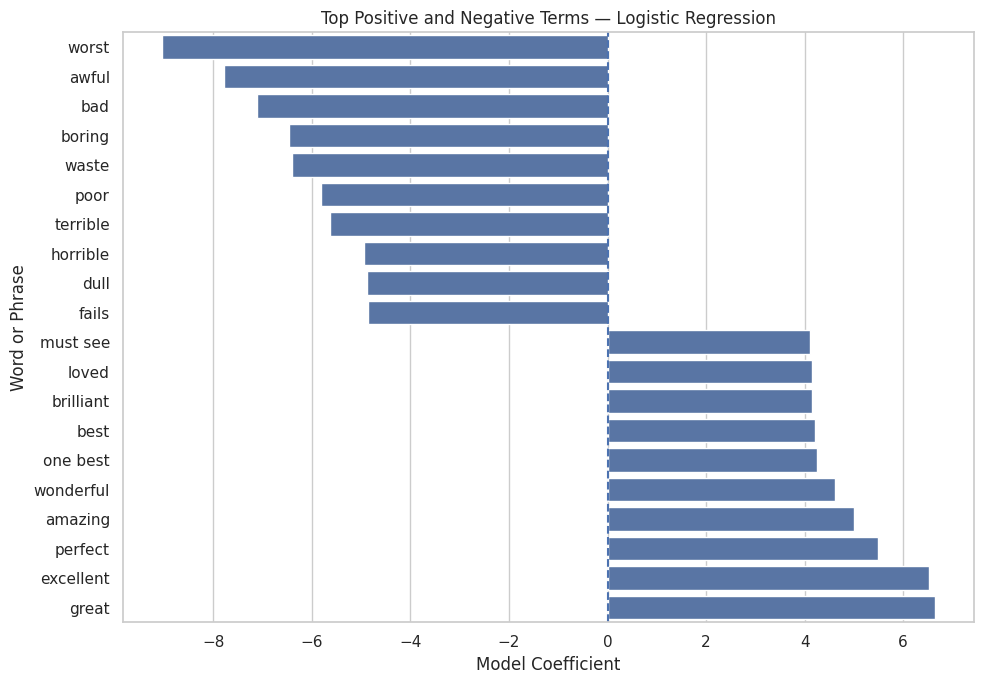

In [19]:
# Extract the trained TF-IDF vectorizer and classifier from Logistic Regression.
lr_vectorizer = lr_pipeline.named_steps["tfidf"]
lr_classifier = lr_pipeline.named_steps["classifier"]

# Get the vocabulary in the same order as the model coefficients.
feature_names = lr_vectorizer.get_feature_names_out()

# Locate the coefficient for the positive class.
positive_index = list(lr_classifier.classes_).index("positive")
coefficients = lr_classifier.coef_[0]

# Create a table containing each word or phrase and its coefficient.
word_importance = pd.DataFrame({
    "Term": feature_names,
    "Coefficient": coefficients
})

# Select the terms with the strongest negative and positive coefficients.
top_negative = word_importance.nsmallest(10, "Coefficient")
top_positive = word_importance.nlargest(10, "Coefficient")

# Display the most negative and positive terms.
print("Terms associated with negative sentiment:")
display(top_negative)

print("Terms associated with positive sentiment:")
display(top_positive)

# Plot the terms with the strongest coefficients.
plot_data = pd.concat([top_negative, top_positive]).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=plot_data,
    x="Coefficient",
    y="Term"
)
plt.axvline(0, linestyle="--")
plt.title("Top Positive and Negative Terms — Logistic Regression")
plt.xlabel("Model Coefficient")
plt.ylabel("Word or Phrase")
plt.tight_layout()

# Save and display the word-importance plot.
plt.savefig(f"{OUTPUT_DIR}/04_top_sentiment_terms.png", dpi=300)
plt.show()

# Save the complete coefficient table for further analysis.
word_importance.sort_values(
    "Coefficient"
).to_csv(f"{OUTPUT_DIR}/word_coefficients.csv", index=False)

# Cell 20 — Create predict_sentiment() for custom reviews

In [20]:
# Select the model with the highest test-set F1-score.
model_objects = {
    "Multinomial Naive Bayes": nb_pipeline,
    "Logistic Regression": lr_pipeline
}

best_model_name = results.iloc[0]["Model"]
best_model = model_objects[best_model_name]

# Define a helper function to classify a new customer or movie review.
def predict_sentiment(review_text):
    # Preprocess the custom text using the same cleaning rules as the training data.
    cleaned_review = preprocess_text(review_text)

    # Return a helpful message if preprocessing removes all words.
    if not cleaned_review.strip():
        return {
            "review": review_text,
            "cleaned_text": cleaned_review,
            "sentiment": "Unable to classify",
            "confidence": None
        }

    # Predict the sentiment label using the selected trained pipeline.
    prediction = best_model.predict([cleaned_review])[0]

    # Obtain class probabilities from the trained model.
    probabilities = best_model.predict_proba([cleaned_review])[0]

    # Find the probability corresponding to the predicted class.
    class_index = list(best_model.classes_).index(prediction)
    confidence = float(probabilities[class_index])

    # Return the prediction and its model probability.
    return {
        "review": review_text,
        "cleaned_text": cleaned_review,
        "sentiment": prediction,
        "confidence": round(confidence, 4)
    }

# Display which model the helper function will use.
print("Selected model:", best_model_name)

Selected model: Logistic Regression


# Cell 21 — Test custom input phrases

In [21]:
# Define example reviews for testing the trained sentiment classifier.
sample_reviews = [
    "This product is amazing and I absolutely love it!",
    "Terrible quality. It broke after one day.",
    "The movie was not good and the acting was disappointing.",
    "Excellent service, fast delivery, and great value.",
    "It is okay, nothing special.",
    "I do not recommend this product."
]

# Predict sentiment for every example review.
for review in sample_reviews:
    result = predict_sentiment(review)

    # Display the original review, predicted sentiment, and model probability.
    print("-" * 70)
    print("Review:", result["review"])
    print("Predicted sentiment:", result["sentiment"])
    print("Confidence:", result["confidence"])

----------------------------------------------------------------------
Review: This product is amazing and I absolutely love it!
Predicted sentiment: positive
Confidence: 0.9652
----------------------------------------------------------------------
Review: Terrible quality. It broke after one day.
Predicted sentiment: negative
Confidence: 0.8647
----------------------------------------------------------------------
Review: The movie was not good and the acting was disappointing.
Predicted sentiment: negative
Confidence: 0.9841
----------------------------------------------------------------------
Review: Excellent service, fast delivery, and great value.
Predicted sentiment: positive
Confidence: 0.9512
----------------------------------------------------------------------
Review: It is okay, nothing special.
Predicted sentiment: negative
Confidence: 0.9761
----------------------------------------------------------------------
Review: I do not recommend this product.
Predicted sentiment

# Cell 22 — Interactive review testing

In [22]:
# Import the interactive text input widget for Google Colab.
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create a text area where the user can type a custom review.
review_input = widgets.Textarea(
    value="The product quality is excellent and delivery was fast.",
    placeholder="Type your product or movie review here...",
    description="Review:",
    layout=widgets.Layout(width="100%", height="120px")
)

# Create a button to trigger sentiment prediction.
predict_button = widgets.Button(
    description="Predict Sentiment",
    button_style="primary"
)

# Create an output area to display the result.
prediction_output = widgets.Output()

# Define the action that runs when the button is clicked.
def on_predict_clicked(button):
    # Clear previous output before showing the new prediction.
    with prediction_output:
        clear_output()

        # Predict the sentiment for the user's review.
        result = predict_sentiment(review_input.value)

        # Display the predicted sentiment and model confidence.
        print("Review:", result["review"])
        print("Sentiment:", result["sentiment"])

        if result["confidence"] is not None:
            print(f"Model probability for predicted class: {result['confidence']:.2%}")
        else:
            print("Please enter a review containing meaningful words.")

# Connect the button to the prediction function.
predict_button.on_click(on_predict_clicked)

# Display the interactive review tester.
display(review_input, predict_button, prediction_output)

Textarea(value='The product quality is excellent and delivery was fast.', description='Review:', layout=Layout…

Button(button_style='primary', description='Predict Sentiment', style=ButtonStyle())

Output()

# Cell 23 — Save trained models

In [23]:
# Import joblib to save scikit-learn pipelines.
import joblib

# Save the trained Naive Bayes pipeline, including its TF-IDF vectorizer.
joblib.dump(
    nb_pipeline,
    f"{OUTPUT_DIR}/naive_bayes_tfidf_model.joblib"
)

# Save the trained Logistic Regression pipeline.
joblib.dump(
    lr_pipeline,
    f"{OUTPUT_DIR}/logistic_regression_tfidf_model.joblib"
)

# Save the best-performing pipeline for convenient future use.
joblib.dump(
    best_model,
    f"{OUTPUT_DIR}/best_sentiment_model.joblib"
)

# Save the text preprocessing function's required NLTK resources separately.
# The prediction notebook should define preprocess_text() before loading the model.
print("All trained model pipelines saved successfully.")

All trained model pipelines saved successfully.


# Cell 24 — Save the final project report

In [24]:
# Define the output path for the project summary.
report_path = f"{OUTPUT_DIR}/final_project_report.txt"

# Write the dataset summary and model evaluation results to a text file.
with open(report_path, "w", encoding="utf-8") as file:
    # Record the project title and dataset information.
    file.write("NLP SENTIMENT CLASSIFICATION USING TF-IDF\n")
    file.write("=" * 50 + "\n\n")
    file.write(f"Dataset path: {DATA_PATH}\n")
    file.write(f"Text column: {TEXT_COLUMN}\n")
    file.write(f"Sentiment column: {LABEL_COLUMN}\n")
    file.write(f"Cleaned dataset rows: {len(df)}\n")
    file.write(f"Training samples: {len(X_train)}\n")
    file.write(f"Testing samples: {len(X_test)}\n\n")

    # Record the test-set performance comparison.
    file.write("TEST-SET MODEL COMPARISON\n")
    file.write(results.to_string(index=False))
    file.write("\n\n")

    # Record the cross-validation benchmark.
    file.write("CROSS-VALIDATION RESULTS\n")
    file.write(cv_results.to_string(index=False))
    file.write("\n\n")

    # Record the model selected for custom review prediction.
    file.write(f"Selected model by test F1-score: {best_model_name}\n")

# Confirm that the report was saved.
print("Final report saved:", report_path)

Final report saved: /content/drive/MyDrive/NLP_Sentiment_Results/final_project_report.txt


# Cell 25 — Create a ZIP file of all results

In [25]:
# Define the ZIP archive path in Colab's temporary storage.
zip_path = "/content/NLP_Sentiment_Results.zip"

# Add all saved charts, CSV files, reports, and model pipelines to the ZIP archive.
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            # Build the complete path for each output file.
            full_path = os.path.join(root, filename)

            # Preserve a clean relative path inside the archive.
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)

            # Add the file to the ZIP archive.
            zip_file.write(full_path, arcname=relative_path)

# Display the ZIP archive location.
print("ZIP archive created:", zip_path)

# Download the completed results archive to your computer.
from google.colab import files
files.download(zip_path)

ZIP archive created: /content/NLP_Sentiment_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Cell 26 — Final verification

In [26]:
# List all generated project files stored in Google Drive.
print("Generated project files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

# Display the final test-set comparison table.
print("\nFinal model performance:")
display(results.round(4))

# Display the cross-validation benchmark.
print("\nCross-validation benchmark:")
display(cv_results.round(4))

# Confirm the selected model for live sentiment predictions.
print("\nSelected sentiment model:", best_model_name)

# Indicate that the complete notebook workflow has finished.
print("\nNLP sentiment classification project completed successfully.")

Generated project files:
- 01_sentiment_distribution.png
- 02_confusion_matrices.png
- 03_model_comparison.png
- 04_top_sentiment_terms.png
- best_sentiment_model.joblib
- classification_reports.txt
- cleaned_sentiment_reviews.csv
- cross_validation_results.csv
- final_project_report.txt
- logistic_regression_tfidf_model.joblib
- model_comparison.csv
- naive_bayes_tfidf_model.joblib
- word_coefficients.csv

Final model performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8953,0.8884,0.9052,0.8967
1,Multinomial Naive Bayes,0.8648,0.8565,0.8776,0.8669



Cross-validation benchmark:


,Model,Mean Accuracy,Accuracy Std,Mean F1,F1 Std
0,Multinomial Naive Bayes,0.8629,0.0046,NaN,NaN
1,Logistic Regression,0.8928,0.0023,NaN,NaN



Selected sentiment model: Logistic Regression

NLP sentiment classification project completed successfully.
